##Системы искусственного интеллекта

##ЛР4. Decision Tree
[10 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

SEED = 42
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')


## Этапы

Задание состоит в детальном изучении данных и построении модели предсказания стоимости объекта недвижимости.

Что входит в работу:

*  Загрузка и предобработка данных.
*  Применение и настройка линейных моделей.
*  Применение и настройка решающего дерева.
*  Сравнение моделей.
*  Оценка важности признаков.


-------------

## Задание

Мы будем работать с данными из [датасета](https://www.kaggle.com/datasets/mrdaniilak/russia-real-estate-20182021), в котором содержится информация об объектах недвижимости в России с их стоимостью за 2018-2021 гг.

*   Цена — Цена в рублях РФ (*числовое*)
*   Дата — дата публикации объявления (*временное*)
*   Время — время публикаци объявления (*временное*)
*   Коорданата x — значение координаты (широта) (*числовое*)
*   Коорданата y — значение координаты (долгота) (*числовое*)
*   Номер — код региона РФ (*категориальное*)
*   Тип здания — тип сооружения, в котором находится квартира (*категориальное*)
*   Этаж — номер этажа, на котором находится квартира (*категориальное* или *числовое*?)
*   Число этажей в доме — общее количество этажей в здании (*категориальное* или *числовое*?)
*   Комнаты — количество комнат в квартире, -1 означает студии с открытой планировкой (*категориальное* или *числовое*?)
*   Площадь — общая площадь квартиры в кв. метрах (*числовое*)
*   Площадь кухни — площадь кухни в кв. метрах (*числовое*)
*   Тип квартиры — тип квартиры, где 1 означает вторичный рынок недвижимости, 11 - новостройка (*категориальное*)

<font color='CornflowerBlue'>**Целевой переменной (target, y)**</font> будем считать цену (столбец `price`)

### **0. Загружаем данные**

In [2]:
import pandas as pd

In [3]:
local_files = [Path('dataset.csv'), Path('Semester5/AISystems/Labwork4/dataset.csv')]
path = next((p for p in local_files if p.is_file()), None)

if path is not None:
    raw = pd.read_csv(path)
else:
    url = ('https://www.kaggle.com/api/v1/datasets/download/'
           'mrdaniilak/russia-real-estate-20182021?datasetVersionNumber=3')
    with TemporaryDirectory() as folder:
        archive = Path(folder) / 'real_estate.zip'
        urlretrieve(url, archive)
        with ZipFile(archive) as zipped, zipped.open('all_v2.csv') as csv_file:
            parts = [chunk.loc[chunk['region'].eq(4189)].copy()
                     for chunk in pd.read_csv(csv_file, chunksize=250_000)]
        raw = pd.concat(parts, ignore_index=True)


In [4]:
raw = raw.loc[raw['region'].eq(4189)].copy()
print('Костромская область:', len(raw), 'объявлений')
display(raw.head())


Костромская область: 5590 объявлений


,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,2550000,2018-11-29,11:48:48,57.780,40.940,4189,3,1,3,4,80.500,12.000,1
1,1350000,2018-11-29,12:53:21,57.827,40.881,4189,2,1,2,2,46.000,10.000,11
2,6500000,2018-11-29,13:03:49,57.768,40.927,4189,3,3,3,3,88.000,15.000,1
3,4900000,2018-11-29,13:20:58,57.780,40.932,4189,3,3,3,3,84.000,18.000,1
4,2100000,2018-11-29,13:36:02,57.768,40.927,4189,3,1,5,3,51.000,6.000,1


In [5]:
region_name = {
    '2661': 'Санкт-Петербург',
    '3446': 'Ленинградская область',
    '3': 'Москва',
    '81': 'Московская область',
    '2843': 'Краснодарский край',
    '2871': 'Нижегородская область',
    '3230': 'Ростовская область',
    '3106': 'Самарская область',
    '2922': 'Республика Татарстан',
    '2900': 'Ставропольский край',
    '2722': 'Республика Башкортостан',
    '6171': 'Свердловская область',
    '4417': 'Республика Коми',
    '5282': 'Челябинская область',
    '5368': 'Иркутская область',
    '5520': 'Пермский край',
    '6817': 'Алтайский край',
    '9579': 'Республика Бурятия',
    '2604': 'Ярославская область',
    '1010': 'Удмуртская Республика',
    '7793': 'Псковская область',
    '13919': 'Республика Северная Осетия — Алания',
    '2860': 'Кемеровская область',
    '3019': 'Чувашская Республика',
    '4982': 'Республика Марий Эл',
    '9648': 'Кабардино-Балкарская Республика',
    '5241': 'Республика Мордовия',
    '3870': 'Красноярский край',
    '3991': 'Тюменская область',
    '2359': 'Республика Хакасия',
    '9654': 'Новосибирская область',
    '2072': 'Воронежская область',
    '8090': 'Республика Карелия',
    '4007': 'Республика Дагестан',
    '11171': 'Республика Саха (Якутия)',
    '10160': 'Забайкальский край',
    '7873, 6937': 'Республика Крым',
    '2594': 'Кировская область',
    '8509': 'Республика Калмыкия',
    '11416': 'Республика Адыгея',
    '11991': 'Карачаево-Черкесская Республика',
    '5178': 'Республика Тыва',
    '13913': 'Республика Ингушетия',
    '6309': 'Республика Алтай',
    '5952': 'Белгородская область',
    '6543': 'Архангельская область',
    '2880': 'Тверская область',
    '5993': 'Пензенская область',
    '2484': 'Ханты-Мансийский автономный округ',
    '4240': 'Липецкая область',
    '5789': 'Владимирская область',
    '14880': 'Ямало-Ненецкий автономный округ',
    '1491': 'Рязанская область',
    '2885': 'Чеченская Республика',
    '5794': 'Смоленская область',
    '2528': 'Саратовская область',
    '4374': 'Вологодская область',
    '4695': 'Волгоградская область',
    '2328': 'Калужская область',
    '5143': 'Тульская область',
    '2806': 'Тамбовская область',
    '14368': 'Мурманская область',
    '5736': 'Новгородская область',
    '7121': 'Курская область',
    '4086': 'Хабаровский край',
    '821': 'Брянская область',
    '10582': 'Астраханская область',
    '7896': 'Калининградская область',
    '8640': 'Омская область',
    '5703': 'Курганская область',
    '10201': 'Томская область',
    '4249': 'Ульяновская область',
    '3153': 'Оренбургская область',
    '4189': 'Костромская область',
    '2814': 'Орловская область',
    '13098': 'Камчатский край',
    '8894': 'Ивановская область',
    '7929': 'Амурская область',
    '16705': 'Магаданская область',
    '69': 'Еврейская автономная область',
    '4963': 'Приморский край',
    '1901': 'Сахалинская область',
    '61888': 'Ненецкий автономный округ'
}

### **<font color='DarkOrange'> Задача 1. [1 балл]</font>**

1.Сделайте первичную обработку данных:

1.1. Выберите один любой регион/город, для которого достаточно данных для построения модели, и оставьте выборку только для этого региона/города. Напишите, какой город выбрали

1.2. Удалите некорректные записи и выбросы

1.3. Создайте дополнительную колонку 'year' - год продажи

1.4. Удалите колонки 'date' и 'time'

1.5. Исключите 1% с каждого хвоста распределения по целевой переменной

1.6. Исключите 1% с каждого хвоста распределения по тем переменным, по которым Вам кажется важно это сделать

1.7. Исследуйте, какие еще признаки можно преобразовать различными способами, например, нелинейная трансформация и пр. Выберите такие признаки и преобразуйте их

Я выбрал Костромскую область: в ней 5 590 объявлений.
Удалил некорректные строки и повторы, оставив последнее объявление с теми же характеристиками.
`year` — год публикации объявления: даты сделки в данных нет.

На отдельных 10% данных я нашёл границы 1% и 99% для цены, общей площади и площади кухни.
По этим границам убрал крайние значения из остальных данных. Эти 10% я не использовал
при обучении и проверке, поэтому границы не зависят от теста. Доля удалённых строк
может немного отличаться от 2%. Результат относится к оставшемуся диапазону цен.

Площади я заменил их логарифмами. Для студий добавил отдельный признак,
а для этажа — его долю от этажности дома и признаки первого и последнего этажей.
Тип здания и тип квартиры закодировал отдельными столбцами. Этажность и число комнат оставил числами.


In [6]:
selected = raw.loc[raw['region'].eq(4189)].copy()
audit = [{'Этап': 'Регион: Костромская область', 'Осталось': len(selected), 'Удалено': 0}]

def note(stage, before, frame):
    audit.append({'Этап': stage, 'Осталось': len(frame), 'Удалено': before - len(frame)})

before = len(selected)
selected = selected.drop_duplicates().copy()
note('Точные дубликаты', before, selected)
selected['timestamp'] = pd.to_datetime(
    selected['date'].astype(str) + ' ' + selected['time'].astype(str), errors='coerce')
num_original = raw.select_dtypes(include='number').columns.tolist()
valid = (selected[num_original].notna().all(axis=1)
    & np.isfinite(selected[num_original]).all(axis=1)
    & selected['timestamp'].notna()
    & selected['timestamp'].dt.year.between(2018, 2021)
    & selected['price'].gt(0)
    & selected['area'].between(10, 500)
    & selected['kitchen_area'].ge(0) & selected['kitchen_area'].lt(selected['area'])
    & selected['levels'].between(1, 60)
    & selected['level'].ge(1) & selected['level'].le(selected['levels'])
    & selected['geo_lat'].between(-90, 90) & selected['geo_lon'].between(-180, 180)
    & selected['rooms'].isin([-1] + list(range(1, 11)))
    & selected['building_type'].isin(range(6))
    & selected['object_type'].isin([1, 11]))
for column in ['level', 'levels', 'rooms', 'building_type', 'object_type']:
    valid &= selected[column].eq(selected[column].round())
before = len(selected)
selected = selected.loc[valid].copy()
note('Некорректные/неподходящие записи', before, selected)

object_key = ['geo_lat', 'geo_lon', 'building_type', 'level', 'levels',
              'rooms', 'area', 'kitchen_area', 'object_type']
before = len(selected)
selected = (selected.sort_values('timestamp', kind='stable')
            .drop_duplicates(subset=object_key, keep='last').copy())
note('Повторные характеристики: последнее объявление', before, selected)
selected['year'] = selected['timestamp'].dt.year.astype(int)
selected = selected.drop(columns=['date', 'time', 'timestamp']).reset_index(drop=True)

calibration, pool = train_test_split(selected, train_size=.10, random_state=SEED)
tail_columns = ['price', 'area', 'kitchen_area']
bounds = calibration[tail_columns].quantile([.01, .99]).T
bounds.columns = ['q01', 'q99']
inside = pool[tail_columns].ge(bounds['q01']).all(axis=1) & pool[tail_columns].le(bounds['q99']).all(axis=1)
removed_tails = pool.loc[~inside].copy()
data = pool.loc[inside].copy()
note('Отложены 10% для границ', len(selected), pool)
note('Убраны хвосты цены и площадей', len(pool), data)

def engineer(frame):
    result = frame.copy()
    result['is_studio'] = result['rooms'].eq(-1).astype(int)
    result['rooms'] = result['rooms'].clip(lower=0)
    result['log_area'] = np.log1p(result['area'])
    result['log_kitchen_area'] = np.log1p(result['kitchen_area'])
    result['relative_level'] = result['level'] / result['levels']
    result['first_floor'] = result['level'].eq(1).astype(int)
    result['top_floor'] = result['level'].eq(result['levels']).astype(int)
    result[['building_type', 'object_type']] = result[['building_type', 'object_type']].astype(str)
    return result

data = engineer(data)
assert not data[object_key].duplicated().any()
assert set(data.index).isdisjoint(calibration.index)
assert set(data.index).isdisjoint(removed_tails.index)
assert len(data) > 500
display(pd.DataFrame(audit))
display(bounds)
display(pool[tail_columns].lt(bounds['q01']).sum().to_frame('Ниже q01').join(
        pool[tail_columns].gt(bounds['q99']).sum().to_frame('Выше q99')))


,Этап,Осталось,Удалено
0,Регион: Костромская область,5590,0
1,Точные дубликаты,5589,1
2,Некорректные/неподходящие записи,5586,3
3,Повторные характеристики: последнее объявление,4288,1298
4,Отложены 10% для границ,3860,428
5,Убраны хвосты цены и площадей,3657,203


,q01,q99
price,"785,130.000","7,200,000.000"
area,17.378,116.703
kitchen_area,3.000,30.000


,Ниже q01,Выше q99
price,92,47
area,21,49
kitchen_area,28,17


2.Выведите на экран первые строки изменённой таблицы, чтобы проверить, что все преобразования сработали.

In [7]:
display(data.head())
display(data.describe().T)
print('Пропуски:', int(data.isna().sum().sum()))
assert not {'date', 'time'}.intersection(data.columns)
assert data.isna().sum().sum() == 0


,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,year,is_studio,log_area,log_kitchen_area,relative_level,first_floor,top_floor
1221,2500000,57.747,40.911,4189,3,1,5,3,58.000,7.000,1,2020,0,4.078,2.079,0.200,1,0
1421,2200000,57.768,40.927,4189,3,8,9,1,39.400,12.200,11,2020,0,3.699,2.580,0.889,0,0
3113,4450000,57.747,40.923,4189,3,9,9,2,57.000,11.500,1,2021,0,4.060,2.526,1.000,0,1
3687,4320000,57.776,40.915,4189,2,5,5,2,66.900,15.000,1,2021,0,4.218,2.773,1.000,0,1
2564,4850000,57.734,40.999,4189,3,4,9,2,78.100,15.000,1,2020,0,4.371,2.773,0.444,0,0


,count,mean,std,min,25%,50%,75%,max
price,"3,657.000","2,668,308.056","1,103,048.647","790,000.000","1,890,000.000","2,490,000.000","3,300,000.000","7,190,000.000"
geo_lat,"3,657.000",57.765,0.083,57.376,57.744,57.760,57.768,58.477
geo_lon,"3,657.000",40.983,0.394,40.552,40.915,40.932,40.989,45.517
region,"3,657.000","4,189.000",0.000,"4,189.000","4,189.000","4,189.000","4,189.000","4,189.000"
level,"3,657.000",4.057,2.735,1.000,2.000,3.000,5.000,17.000
levels,"3,657.000",6.793,3.229,1.000,5.000,5.000,9.000,19.000
rooms,"3,657.000",1.893,0.881,0.000,1.000,2.000,2.000,9.000
area,"3,657.000",51.773,17.944,17.700,37.800,49.000,62.900,116.000
kitchen_area,"3,657.000",9.719,3.369,3.000,7.700,9.000,11.500,30.000
year,"3,657.000","2,020.132",0.675,"2,018.000","2,020.000","2,020.000","2,021.000","2,021.000"


Пропуски: 0


3. Исследуйте закон распределения целевого признака (напомним, таргетом считаем столбец `price`). Является ли распределение нормальным?

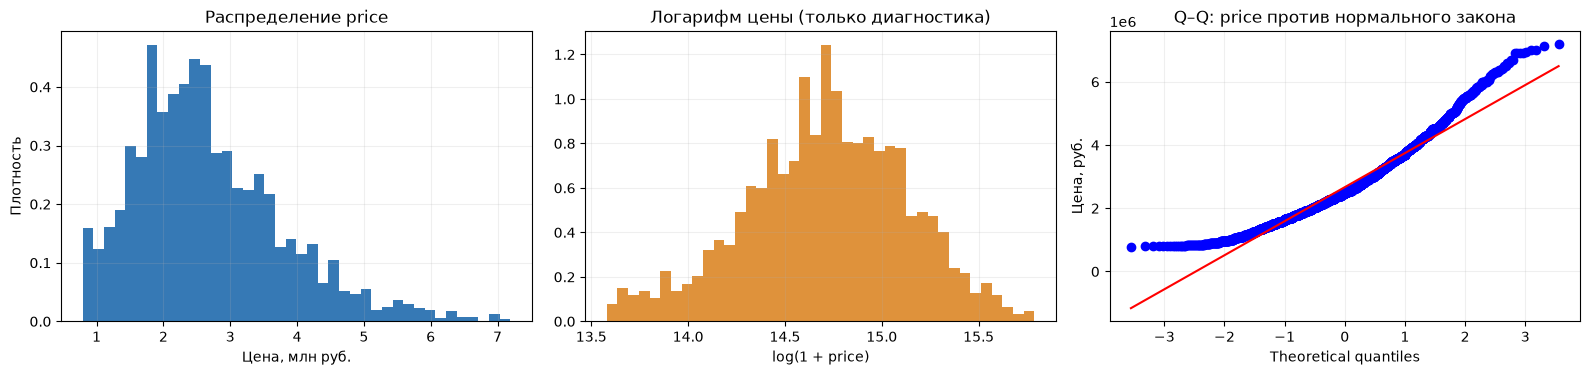

n                                  3,657.000
mean, руб.                     2,668,308.056
median, руб.                   2,490,000.000
skewness                               0.895
excess kurtosis                        0.888
D’Agostino–Pearson statistic         428.080
p-value                                0.000
dtype: float64

Я отверг гипотезу нормального распределения при уровне 0,05 (p = 1.11e-93). Асимметрия равна 0.895. На графике виден длинный правый хвост. Логарифм цены выглядит ближе к нормальному распределению, но для обучения я оставил цену в рублях.

In [8]:
price = data['price']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(price / 1e6, bins=40, color='#3679b5', density=True)
axes[0].set(xlabel='Цена, млн руб.', ylabel='Плотность', title='Распределение price')
axes[1].hist(np.log1p(price), bins=40, color='#df923b', density=True)
axes[1].set(xlabel='log(1 + price)', title='Логарифм цены (только диагностика)')
stats.probplot(price, dist='norm', plot=axes[2])
axes[2].set(title='Q–Q: price против нормального закона', ylabel='Цена, руб.')
fig.tight_layout()
plt.show()
normal_stat, normal_p = stats.normaltest(price)
normal_summary = pd.Series({'n': len(price), 'mean, руб.': price.mean(),
    'median, руб.': price.median(), 'skewness': stats.skew(price),
    'excess kurtosis': stats.kurtosis(price), 'D’Agostino–Pearson statistic': normal_stat,
    'p-value': normal_p})
display(normal_summary)

verdict = 'отверг' if normal_p < .05 else 'не отверг'
display(Markdown(f'Я {verdict} гипотезу нормального распределения при уровне 0,05 '
    f'(p = {normal_p:.3g}). Асимметрия равна {stats.skew(price):.3f}. '
    'На графике виден длинный правый хвост. Логарифм цены выглядит ближе к нормальному '
    'распределению, но для обучения я оставил цену в рублях.'))


### **<font color='DarkOrange'> Задача 2. [1 балл]</font>**

Подготовка к обучению

1. Создайте матрицу объект-признак  `X` и вектор с целевой переменной (price) `y`.

In [9]:
numeric = ['geo_lat', 'geo_lon', 'level', 'levels', 'rooms', 'year',
           'log_area', 'log_kitchen_area', 'relative_level', 'is_studio',
           'first_floor', 'top_floor']
categorical = ['building_type', 'object_type']
features = numeric + categorical
X = data[features].copy()
y = data['price'].copy()
assert 'price' not in X and 'region' not in X
print('X:', X.shape, '| y:', y.shape)


X: (3657, 14) | y: (3657,)



2. Разбейте данные на тренировочную и тестовую части, размер тестовой части — 30%.


In [10]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=.30, random_state=SEED)
assert X_train_raw.index.intersection(X_test_raw.index).empty
print('Обучение:', len(X_train_raw), '| Тест:', len(X_test_raw))


Обучение: 2559 | Тест: 1098


3. Для линейных моделей важно применить нормализацию, возьмем StandardScaler, обучим метод на тренировочных данных и применим его и к трейну, и к тесту.

In [11]:
def make_preprocessor(scale=True):
    return ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical),
    ], sparse_threshold=0, verbose_feature_names_out=False)

preprocessor = make_preprocessor(scale=True)
train_array = preprocessor.fit_transform(X_train_raw)  # fit только на train
scaler = preprocessor.named_transformers_['num']
test_array = preprocessor.transform(X_test_raw)
assert np.allclose(scaler.mean_, X_train_raw[numeric].mean().to_numpy())


4. После масштабирования признаков `X_train` и `X_test` перестали быть объектами типа `pd.DataFrame`, это неудобно. Приведите их снова к `pd.DataFrame`.

In [12]:
feature_names = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(train_array, index=X_train_raw.index, columns=feature_names)
X_test = pd.DataFrame(test_array, index=X_test_raw.index, columns=feature_names)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
display(X_train.head())


,geo_lat,geo_lon,level,levels,rooms,year,log_area,log_kitchen_area,relative_level,is_studio,first_floor,top_floor,building_type_1,building_type_2,building_type_3,building_type_4,building_type_5,object_type_11
2995,-0.038,0.111,-1.135,-0.568,1.264,-0.204,0.817,-0.445,-1.473,-0.091,2.168,-0.509,1.000,0.000,0.000,0.000,0.000,0.000
3288,0.103,-0.100,-0.773,0.657,0.127,1.293,0.196,-0.598,-1.395,-0.091,-0.461,-0.509,0.000,0.000,1.000,0.000,0.000,0.000
4123,-0.118,-0.275,-0.411,-1.181,1.264,1.293,1.078,0.717,1.332,-0.091,-0.461,1.966,0.000,0.000,1.000,0.000,0.000,0.000
3300,-1.462,0.457,-0.773,-1.488,-1.011,1.293,-0.720,-0.445,1.332,-0.091,-0.461,1.966,0.000,0.000,1.000,0.000,0.000,0.000
721,0.272,-0.072,-0.411,-0.568,-1.011,-0.204,-1.296,-1.292,-0.070,-0.091,-0.461,-0.509,0.000,0.000,1.000,0.000,0.000,0.000


### **<font color='DarkOrange'> Задача 3. [1 балл]</font>**

Обучите на тренировочных данных с параметрами по умолчанию:

1) линейную регрессию Ridge;

2) метод опорных векторов [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) (с kernel='linear').

<font color='OrangeRed'>**Важно!**</font> SVR может долго обучаться без нормализации данных, возьмите на заметку

In [13]:
ridge_default = Ridge()
ridge_default.fit(X_train, y_train)


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [14]:
svr_default = SVR(kernel='linear')
svr_default.fit(X_train, y_train)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


3) С помощью обученных моделей сделайте предсказание на тестовых данных. Вычислите значение метрики [RMSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) на тесте.

In [15]:
def metrics(y_true, prediction):
    return {'RMSE, руб.': np.sqrt(mean_squared_error(y_true, prediction)),
            'MAE, руб.': mean_absolute_error(y_true, prediction),
            'R²': r2_score(y_true, prediction)}

baseline_models = {'Ridge default': ridge_default, 'SVR linear default': svr_default}
baseline_rows = []
for name, model in baseline_models.items():
    prediction = model.predict(X_test)
    baseline_rows.append({'Модель': name, **metrics(y_test, prediction),
        'Train RMSE, руб.': metrics(y_train, model.predict(X_train))['RMSE, руб.']})
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
baseline_rows.append({'Модель': 'Dummy mean', **metrics(y_test, dummy.predict(X_test)),
    'Train RMSE, руб.': metrics(y_train, dummy.predict(X_train))['RMSE, руб.']})
display(pd.DataFrame(baseline_rows).set_index('Модель'))


,"RMSE, руб.","MAE, руб.",R²,"Train RMSE, руб."
Модель,,,,
Ridge default,"593,820.699","443,756.949",0.700,"596,524.636"
SVR linear default,"1,087,823.890","826,064.832",-0.007,"1,123,366.332"
Dummy mean,"1,086,689.081","855,174.845",-0.004,"1,110,081.738"


Я обучил SVR со стандартными параметрами и линейным ядром.
Дополнительно при подборе параметров проверил, помогает ли масштабирование цены.


### **<font color='DarkOrange'> Задача 4. [2 баллa]</font>**

Обучите [решающее дерево](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor) с параметрами по умолчанию на тренировочных данных, сделайте предсказание на тесте и вычислите на тесте RMSE

In [16]:
tree_default = DecisionTreeRegressor(random_state=SEED).fit(X_train, y_train)
baseline_models['Tree default'] = tree_default
tree_prediction = tree_default.predict(X_test)
baseline_rows.append({'Модель': 'Tree default', **metrics(y_test, tree_prediction),
    'Train RMSE, руб.': metrics(y_train, tree_default.predict(X_train))['RMSE, руб.']})
display(pd.DataFrame(baseline_rows).set_index('Модель'))
print('Глубина:', tree_default.get_depth(), '| листьев:', tree_default.get_n_leaves())


,"RMSE, руб.","MAE, руб.",R²,"Train RMSE, руб."
Модель,,,,
Ridge default,"593,820.699","443,756.949",0.700,"596,524.636"
SVR linear default,"1,087,823.890","826,064.832",-0.007,"1,123,366.332"
Dummy mean,"1,086,689.081","855,174.845",-0.004,"1,110,081.738"
Tree default,"649,859.950","402,924.109",0.641,0.000


Глубина: 28 | листьев: 2316


Нужно ли масшабировать признаки для обучения решающего дерева? Проверьте это, заново разбив данные на тренировочную и тестовую части (назовите новые полученные объекты новыми названиями), и проведите обучение, предсказание и оценку метрики до масштабирования и после.

<font color='LightSteelBlue'>**Подсказка:**</font> Можно использовать любой метод мастшабирования признаков

In [17]:
X_train_tree_raw, X_test_tree_raw, y_train_tree, y_test_tree = train_test_split(
    X, y, test_size=.30, random_state=SEED + 1)
tree_encoder = make_preprocessor(scale=False)
X_train_tree_unscaled = tree_encoder.fit_transform(X_train_tree_raw)
X_test_tree_unscaled = tree_encoder.transform(X_test_tree_raw)
tree_scaler = StandardScaler().fit(X_train_tree_unscaled)
X_train_tree_scaled = tree_scaler.transform(X_train_tree_unscaled)
X_test_tree_scaled = tree_scaler.transform(X_test_tree_unscaled)
tree_before_scale = DecisionTreeRegressor(random_state=SEED).fit(X_train_tree_unscaled, y_train_tree)
tree_after_scale = DecisionTreeRegressor(random_state=SEED).fit(X_train_tree_scaled, y_train_tree)
pred_before_scale = tree_before_scale.predict(X_test_tree_unscaled)
pred_after_scale = tree_after_scale.predict(X_test_tree_scaled)
scale_comparison = pd.DataFrame([
    {'Обработка': 'Без масштабирования', **metrics(y_test_tree, pred_before_scale)},
    {'Обработка': 'StandardScaler', **metrics(y_test_tree, pred_after_scale)},
]).set_index('Обработка')
display(scale_comparison)
changed_predictions = np.count_nonzero(~np.isclose(pred_before_scale, pred_after_scale))
print('Отличающихся прогнозов:', changed_predictions, 'из', len(y_test_tree))
print('Средний |Δ прогноза|, руб.:', np.mean(np.abs(pred_before_scale - pred_after_scale)))


,"RMSE, руб.","MAE, руб.",R²
Обработка,,,
Без масштабирования,"634,642.799","414,294.270",0.664
StandardScaler,"636,762.500","413,532.474",0.662


Отличающихся прогнозов: 139 из 1098
Средний |Δ прогноза|, руб.: 45643.79143897996


Какой вывод про масштабирование признаков для обучения дерева можно сделать?

Я сравнил два дерева на одинаковом новом разбиении.
Масштабирование дереву не требуется: порядок значений и возможные разбиения сохраняются.
Разница в прогнозах возможна из-за округления чисел.


In [18]:
rmse_before = scale_comparison.loc['Без масштабирования', 'RMSE, руб.']
rmse_after = scale_comparison.loc['StandardScaler', 'RMSE, руб.']
display(Markdown(f'Я получил RMSE {rmse_before:,.0f} руб. без масштабирования '
    f'и {rmse_after:,.0f} руб. после него. Разница: {rmse_after - rmse_before:+,.0f} руб.'))


Я получил RMSE 634,643 руб. без масштабирования и 636,763 руб. после него. Разница: +2,120 руб.

### **<font color='DarkOrange'> Задача 5. [3 баллa]</font>**

Теперь ваша цель — максимально улучшить модели

Для этого:

1) у линейных моделей:
  * `SVR` (если смогли обучить модель) - подберите гиперпараметр `С` (переберите $20$ значений `C` в диапазоне от $0.1$ до $10$ с равным шагом);
  * `Ridge` - подберите гиперпараметр $\alpha$ (переберите $20$ значений $\alpha$ в диапазоне от $10^{-3}$ до $10^{3}$ с равным логарифмическим шагом)

2) у решающего дерева подберите `max_depth` (переберите глубину от $1$ до $10$ с шагом $1$) и `criterion` — `squared_error` или `absolute_error` (см. [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor)).

Для подбора параметров используйте [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) с `5` фолдами и метрикой `r2`.

**<font color='OrangeRed'> Важно! </font>** Подбор параметров осуществляется только по тренировочным данным! Контролируйте свои пайплайны обучения на предмет ликов!

Я подбирал параметры только на обучающей части, на пяти одинаковых разбиениях.
Масштабирование и кодирование категорий выполнял заново внутри каждого разбиения.
Тест при подборе не использовал.


3) После подбора гиперпараметров обучите модели с найденными гиперпараметрами на тренировочных данных, сделайте предсказания на тесте и оцените их качество (`RMSE`).

Ridge tuned {'model__alpha': np.float64(1.438449888287663)} CV R²=0.7059


SVR linear tuned (рубли) {'model__C': np.float64(10.0)} CV R²=0.0107


Tree tuned {'model__criterion': 'squared_error', 'model__max_depth': 9} CV R²=0.7190


SVR linear tuned (+scale y) {'model__regressor__C': np.float64(2.18421052631579)} CV R²=0.7000


,CV R²,CV R² std,Train CV R²,Параметры,"Время, с"
Модель,,,,,
Tree tuned,0.719,0.020,0.897,"{'model__criterion': 'squared_error', 'model__...",1.177
Ridge tuned,0.706,0.006,0.712,{'model__alpha': 1.438449888287663},1.421
SVR linear tuned (+scale y),0.700,0.007,0.705,{'model__regressor__C': 2.18421052631579},38.313
SVR linear tuned (рубли),0.011,0.015,0.012,{'model__C': 10.0},6.487


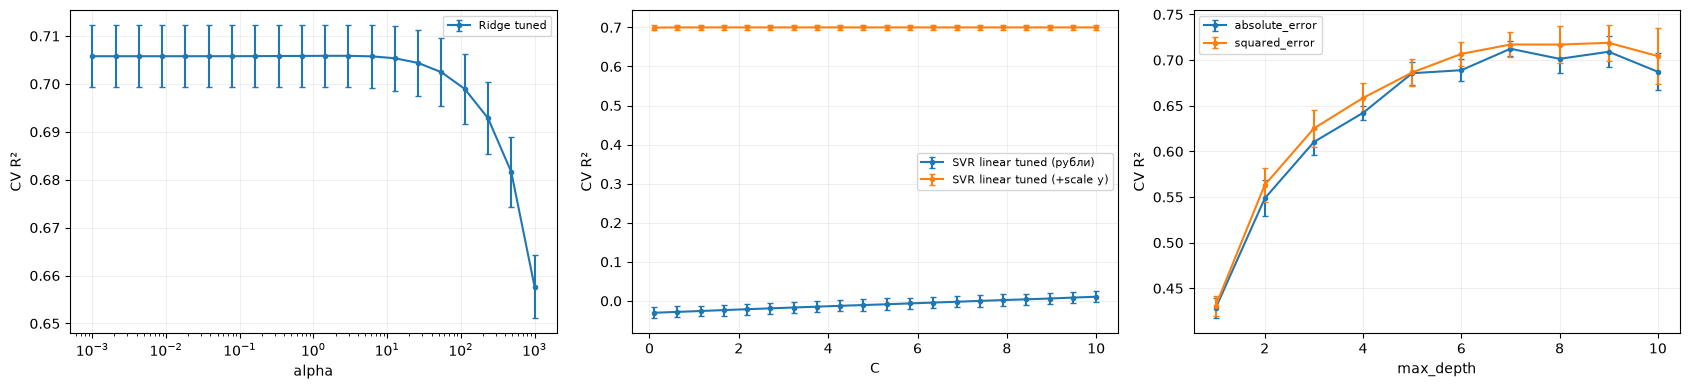

Выбор по обучающей CV: Tree tuned


In [19]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train_raw, y_train))
for train_idx, valid_idx in cv_splits:
    assert not set(train_idx).intersection(valid_idx)
assert sorted(np.concatenate([v for _, v in cv_splits])) == list(range(len(X_train_raw)))

def model_pipeline(model, scale=True):
    return Pipeline([('preprocess', make_preprocessor(scale)), ('model', model)])

experiments = {
    'Ridge tuned': (model_pipeline(Ridge()),
                    {'model__alpha': np.logspace(-3, 3, 20)}),
    'SVR linear tuned (рубли)': (model_pipeline(SVR(kernel='linear')),
                    {'model__C': np.linspace(.1, 10, 20)}),
    'Tree tuned': (model_pipeline(DecisionTreeRegressor(random_state=SEED), scale=False),
                    {'model__max_depth': list(range(1, 11)),
                     'model__criterion': ['squared_error', 'absolute_error']}),
    'SVR linear tuned (+scale y)': (model_pipeline(TransformedTargetRegressor(
                        regressor=SVR(kernel='linear'), transformer=StandardScaler())),
                    {'model__regressor__C': np.linspace(.1, 10, 20)}),
}
searches, cv_rows = {}, []
for name, (estimator, grid) in experiments.items():
    start = perf_counter()
    search = GridSearchCV(estimator, grid, scoring='r2', cv=cv_splits,
                          n_jobs=2, refit=True, error_score='raise', return_train_score=True)
    search.fit(X_train_raw, y_train)
    searches[name] = search
    assert len(search.cv_results_['params']) == 20
    assert search.n_splits_ == 5
    assert np.isfinite(search.cv_results_['mean_test_score']).all()
    cv_rows.append({'Модель': name, 'CV R²': search.best_score_,
        'CV R² std': search.cv_results_['std_test_score'][search.best_index_],
        'Train CV R²': search.cv_results_['mean_train_score'][search.best_index_],
        'Параметры': search.best_params_, 'Время, с': perf_counter() - start})
    print(name, search.best_params_, f'CV R²={search.best_score_:.4f}', flush=True)
cv_results = pd.DataFrame(cv_rows).set_index('Модель').sort_values('CV R²', ascending=False)
display(cv_results)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name, parameter in [
    (axes[0], 'Ridge tuned', 'model__alpha'),
    (axes[1], 'SVR linear tuned (рубли)', 'model__C'),
    (axes[1], 'SVR linear tuned (+scale y)', 'model__regressor__C'),
]:
    result = searches[name].cv_results_
    ax.errorbar(np.array(result['param_' + parameter], dtype=float),
                result['mean_test_score'], yerr=result['std_test_score'],
                marker='.', label=name, capsize=2)
    ax.set(xlabel='alpha' if ax is axes[0] else 'C', ylabel='CV R²')
    ax.legend(fontsize=8)
axes[0].set_xscale('log')
tree_cv = pd.DataFrame(searches['Tree tuned'].cv_results_)
for criterion, part in tree_cv.groupby('param_model__criterion'):
    axes[2].errorbar(part['param_model__max_depth'].astype(int), part['mean_test_score'],
                    yerr=part['std_test_score'], marker='.', label=criterion, capsize=2)
axes[2].set(xlabel='max_depth', ylabel='CV R²')
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()
cv_winner = cv_results.index[0]
print('Выбор по обучающей CV:', cv_winner)


Какая модель справилась с решением задачи лучше всего по метрике RMSE?

<font color='LightSteelBlue'>**Подсказка:**</font> Оформите полученные метрики в `pd.DataFrame`

In [20]:
comparison_rows = list(baseline_rows)
for name, search in searches.items():
    best_model = search.best_estimator_
    comparison_rows.append({'Модель': name,
        **metrics(y_test, best_model.predict(X_test_raw)),
        'Train RMSE, руб.': metrics(y_train, best_model.predict(X_train_raw))['RMSE, руб.']})
comparison = pd.DataFrame(comparison_rows).set_index('Модель').sort_values('RMSE, руб.')
display(comparison)
required_names = ['Ridge tuned', 'SVR linear tuned (рубли)', 'Tree tuned']
required_winner = comparison.loc[required_names, 'RMSE, руб.'].idxmin()
test_winner = comparison.loc[list(searches), 'RMSE, руб.'].idxmin()
assert np.isfinite(comparison.select_dtypes('number').to_numpy()).all()

display(Markdown(f'Среди настроенных моделей я получил наименьший RMSE у **{test_winner}**: '
    f'**{comparison.loc[test_winner, "RMSE, руб."]:,.0f} руб.** '
    f'При подборе параметров лучший средний R² был у **{cv_winner}**. '
    'По результатам теста я параметры заново не менял.'))


,"RMSE, руб.","MAE, руб.",R²,"Train RMSE, руб."
Модель,,,,
Ridge default,"593,820.699","443,756.949",0.700,"596,524.636"
Ridge tuned,"593,849.116","443,806.557",0.700,"596,542.751"
SVR linear tuned (+scale y),"596,116.541","438,532.201",0.698,"603,089.444"
Tree tuned,"606,180.366","405,822.439",0.687,"373,119.143"
Tree default,"649,859.950","402,924.109",0.641,0.000
SVR linear tuned (рубли),"1,062,446.081","803,829.950",0.040,"1,097,866.017"
Dummy mean,"1,086,689.081","855,174.845",-0.004,"1,110,081.738"
SVR linear default,"1,087,823.890","826,064.832",-0.007,"1,123,366.332"


Среди настроенных моделей я получил наименьший RMSE у **Ridge tuned**: **593,849 руб.** При подборе параметров лучший средний R² был у **Tree tuned**. По результатам теста я параметры заново не менял.

Вывод:


В таблице я сравнил ошибки до и после подбора параметров.
Для Ridge результат почти не изменился. Ограничение глубины улучшило результат дерева.
SVR лучше работал после масштабирования цены: значения C из заданного диапазона
оказались слишком малы для исходных цен в рублях.


### **<font color='DarkOrange'> Задача 6. [1 балл]</font>**

Постройте диаграммы (горизонтальные бары) важности признаков для линейной регрессии и дерева (для линейных моделей берите модуль значений весов). Сравните между собой списки из трёх самых важных признаков. Совпадают ли они?

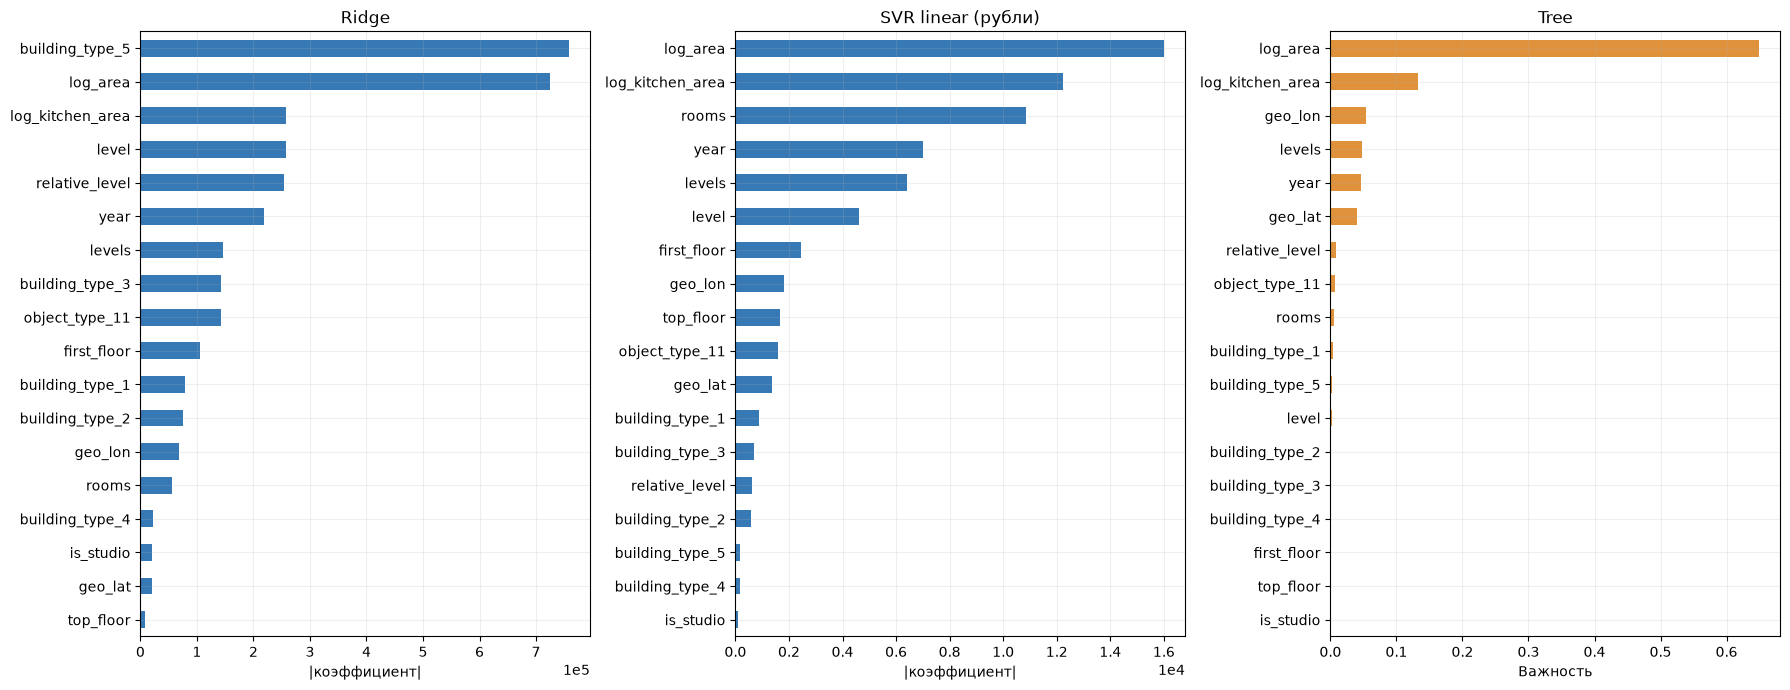

,Ridge,SVR linear (рубли),Tree
1,building_type_5,log_area,log_area
2,log_area,log_kitchen_area,log_kitchen_area
3,log_kitchen_area,rooms,geo_lon


Я получил разные тройки признаков. Общие признаки: log_area, log_kitchen_area.

In [21]:
ridge_best = searches['Ridge tuned'].best_estimator_
svr_best = searches['SVR linear tuned (рубли)'].best_estimator_
tree_best = searches['Tree tuned'].best_estimator_
importance = {}
for name, pipeline in [('Ridge', ridge_best), ('SVR linear (рубли)', svr_best),
                       ('Tree', tree_best)]:
    names = pipeline.named_steps['preprocess'].get_feature_names_out()
    model = pipeline.named_steps['model']
    weights = model.feature_importances_ if name == 'Tree' else np.abs(model.coef_).ravel()
    importance[name] = pd.Series(weights, index=names).sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (name, values) in zip(axes, importance.items()):
    values.sort_values().plot.barh(ax=ax, color='#3679b5' if name != 'Tree' else '#df923b')
    ax.set(title=name, xlabel='Важность' if name == 'Tree' else '|коэффициент|')
    if name != 'Tree':
        ax.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
fig.tight_layout()
plt.show()
top3 = pd.DataFrame({name: values.head(3).index.tolist() for name, values in importance.items()},
                    index=['1', '2', '3'])
display(top3)
common = set(top3['Ridge']) & set(top3['Tree'])

display(Markdown('Я получил '
    + ('одинаковые тройки признаков.' if set(top3['Ridge']) == set(top3['Tree']) else 'разные тройки признаков.')
    + ' Общие признаки: ' + (', '.join(sorted(common)) or 'нет') + '.'))


Я сравнил три самых важных признака у Ridge и дерева.
Для линейных моделей взял модули коэффициентов, для дерева — важности признаков.
Сравнивал их порядок, поскольку сами значения рассчитаны по-разному.


### **<font color='DarkOrange'> Задача 7. [1 балл]</font>**

Сделайте выводы по самой лучшей модели:

1. Какая модель после подбора гиперпараметров лучше всего решает задачу с точки зрения метрики RMSE?

2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?

3. Как можно еще улучшить получившуюся модель? Как в случае линейной модели, так и для дерева.

Вывод:


1. После подбора параметров лучший результат на тесте я получил у **Ridge tuned**: RMSE = **593,849 руб.**, MAE = **443,807 руб.**, R² = **0.700**.

2. RMSE составляет 24.2% от медианной цены. Для реального использования я бы эту модель не выбрал: ошибка велика, данные старые, а проверка проведена только для одного региона после удаления крайних цен. На новых объявлениях результат может быть хуже.

3. Для линейных моделей я бы добавил расстояние до центра, состояние квартиры и дома, проверил логарифм цены. Для дерева — подобрал минимальное число объектов в листе и попробовал случайный лес. Для обеих моделей нужны свежие данные и проверка на объявлениях за более поздний период.

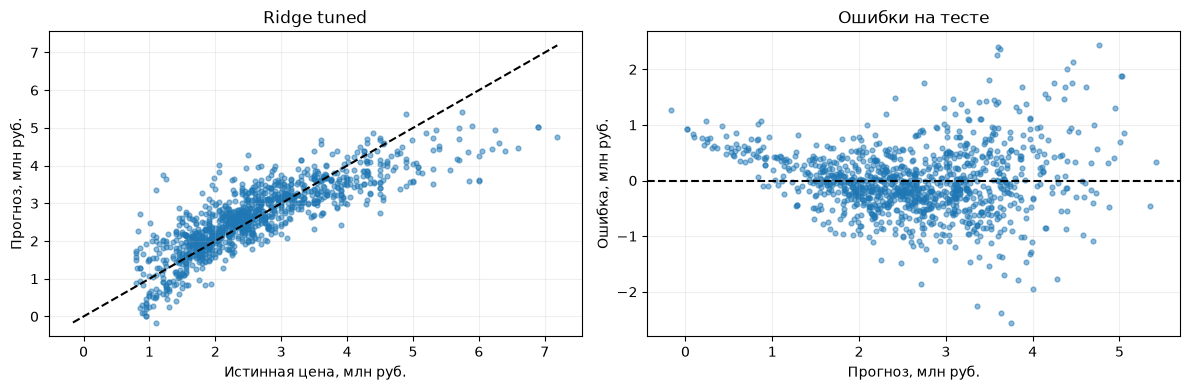

In [22]:
chosen_model = searches[test_winner].best_estimator_
prediction = chosen_model.predict(X_test_raw)
chosen_metrics = metrics(y_test, prediction)
relative_rmse = chosen_metrics['RMSE, руб.'] / y_test.median()
display(Markdown(
    f'1. После подбора параметров лучший результат на тесте я получил у **{test_winner}**: '
    f'RMSE = **{chosen_metrics["RMSE, руб."]:,.0f} руб.**, '
    f'MAE = **{chosen_metrics["MAE, руб."]:,.0f} руб.**, R² = **{chosen_metrics["R²"]:.3f}**.\n\n'
    f'2. RMSE составляет {relative_rmse:.1%} от медианной цены. '
    'Для реального использования я бы эту модель не выбрал: ошибка велика, '
    'данные старые, а проверка проведена только для одного региона после удаления крайних цен. '
    'На новых объявлениях результат может быть хуже.\n\n'
    '3. Для линейных моделей я бы добавил расстояние до центра, состояние квартиры '
    'и дома, проверил логарифм цены. Для дерева — подобрал минимальное число объектов '
    'в листе и попробовал случайный лес. Для обеих моделей нужны свежие данные '
    'и проверка на объявлениях за более поздний период.'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test / 1e6, prediction / 1e6, s=12, alpha=.5)
limits = [min(y_test.min(), prediction.min()) / 1e6, max(y_test.max(), prediction.max()) / 1e6]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Истинная цена, млн руб.', ylabel='Прогноз, млн руб.', title=test_winner)
axes[1].scatter(prediction / 1e6, (y_test - prediction) / 1e6, s=12, alpha=.5)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(xlabel='Прогноз, млн руб.', ylabel='Ошибка, млн руб.', title='Ошибки на тесте')
fig.tight_layout()
plt.show()
